In [1]:
import perf
import pandas as pd

In [2]:
perf.system.info()

,cpu,core,numa,arch,platform,vendor,model,family,stepping,freq,L1i,L1d,L2,L3
0,0,0,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
1,1,4,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
2,2,8,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
3,3,12,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
4,4,16,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
5,5,20,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
6,6,28,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
7,7,29,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
8,8,30,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
9,9,31,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb


In [3]:
perf.system.tune()

,setting,path,before,after
0,aslr,/proc/sys/kernel/randomize_va_space,off,off
1,governor,/sys/devices/system/cpu/cpu*/cpufreq/scaling_g...,performance,performance
2,energy_performance_preference,/sys/devices/system/cpu/cpu*/cpufreq/energy_pe...,performance,performance
3,cpu_frequency,/sys/devices/system/cpu/cpu*/cpufreq/scaling_{...,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz
4,turbo,/sys/devices/system/cpu/intel_pstate/no_turbo,on,on
5,turbo_msr,/dev/cpu/*/msr,,on
6,boost,/sys/devices/system/cpu/cpufreq/boost,,on
7,rdpmc,/sys/devices/*/rdpmc,,
8,smt,/sys/devices/system/cpu/smt/control,on,on
9,nmi_watchdog,/proc/sys/kernel/nmi_watchdog,off,off


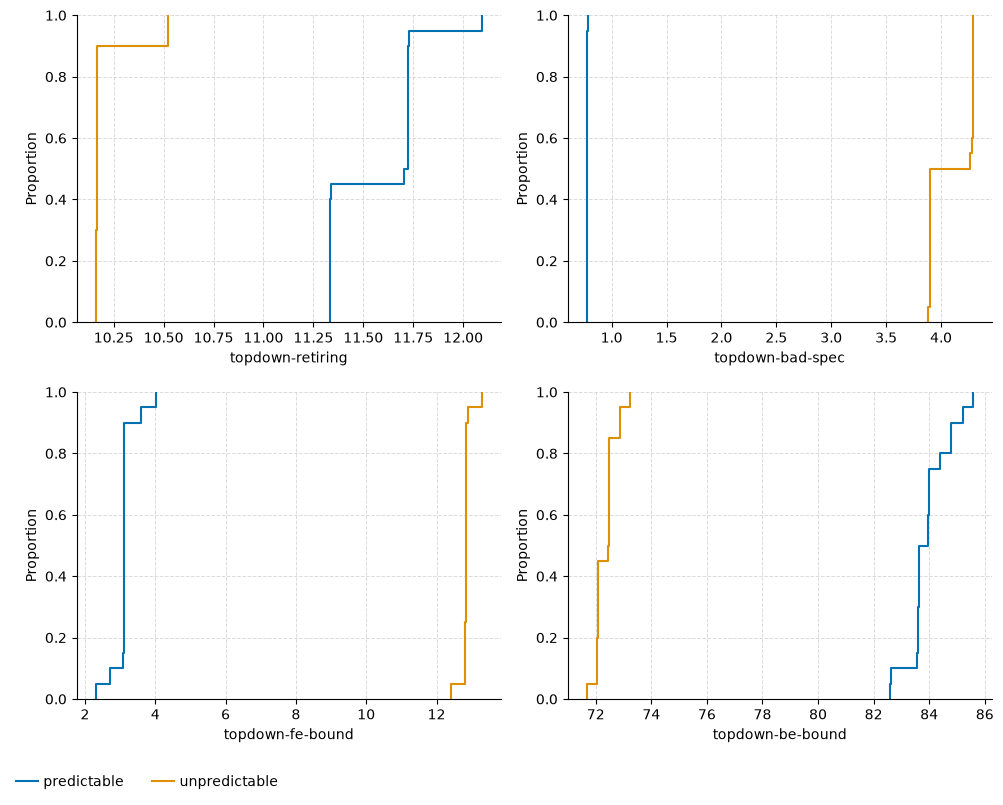

[]

In [4]:
import random

BITS = 2
rng = random.Random(0)
VALUES = [rng.getrandbits(32) for _ in range(16)]
ASM = "\n".join(
    ["xor eax, eax"]
    + [
        line
        for i in range(BITS)
        for line in (
            f"test rdi, {1 << i}",
            f"jz .L{i}",
            f"add rax, {i + 1}",
            f".L{i}:",
        )
    ]
    + ["ret"]
)
CONFIG = {
    "branch": ["predictable", "unpredictable"],
    "dcache": "hot",
    "icache": "hot",
    "dtlb": "hot",
    "itlb": "hot",
    "samples": 100,
    "iterations": 10000,
}
top = perf.benchmark(
    asm=ASM,
    mode=["latency"],
    event=["topdown*"],
    config=CONFIG,
    data={"regs": {"rdi": VALUES}},
)
perf.plot(top, "ecdf", event=[c for c in top.columns if c.startswith("topdown-")], groupby="config.branch")

In [5]:
btb = perf.benchmark(
    asm=ASM,
    mode=["latency"],
    event=["cycles", "instructions", "branch-misses"],
    config=CONFIG,
    data={"regs": {"rdi": VALUES}},
)
summary = btb.groupby("config.branch")[["cycles", "instructions", "branch-misses"]].mean()
penalty = summary.loc["unpredictable"] - summary.loc["predictable"]
summary.loc["penalty"] = penalty
summary.loc["penalty/branch"] = penalty / BITS
summary.round(2)

,cycles,instructions,branch-misses
config.branch,,,
predictable,1.48,4.88,0.00
unpredictable,28.03,4.87,0.90
penalty,26.56,-0.00,0.90
penalty/branch,13.28,-0.00,0.45


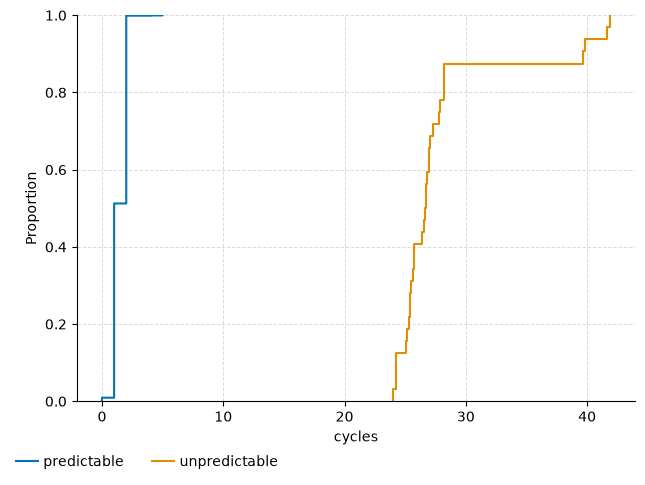

[]

In [6]:
perf.plot(btb, "ecdf", event="cycles", groupby="config.branch")